# 06. Evaluación final: SynthSeg vs Clásico vs Híbrido

**Partición por paciente** (los estudios de un mismo niño quedan en el mismo grupo), estratificada por rango de volumen:
- **Train 70%**: calibrar los parámetros de decisión del híbrido (umbral de volumen, fracción de falla)
- **Validación 10%**: elegir entre las variantes del híbrido (H1 vs H2) con los parámetros calibrados
- **Test 20%**: evaluación final, solo una vez, sin tocar nada

**Qué se "entrena" en cada método**
| Método | Parámetros | Dónde se fijan |
|---|---|---|
| SynthSeg | red preentrenada por sus autores | ninguno |
| Clásico | umbrales y radios morfológicos | ya fijados en el notebook 03 (los 8 casos de desarrollo se fuerzan a train) |
| Híbrido | `UMBRAL_ML`, `FRAC_FALLA`, variante H1/H2 | train + validación |

Salidas en `outputs/figuras_06_final/`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import shutil
import time
import itertools
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import wilcoxon

from src.io import list_scans, load, load_seg
from src.paths import OUTPUTS
import src.clasico as clasico

FIG_DIR = OUTPUTS / "figuras_06_final"
if FIG_DIR.exists():
    shutil.rmtree(FIG_DIR)
FIG_DIR.mkdir(parents=True)

def guardar(nombre, dpi=110):
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

SEED = 42
FRAC_TRAIN, FRAC_VAL, FRAC_TEST = 0.70, 0.10, 0.20
DESARROLLO = ["sub_036", "sub_007", "sub_018", "sub_035", "sub_038", "sub_028", "sub_041", "sub_015"]
FS_VENT = [4, 5, 43, 44]
RECALCULAR = False
CACHE = OUTPUTS / "figuras_05_hibrido" / "base_synthseg_clasico.csv"

scans = list_scans()
print(len(scans), "estudios")

45 estudios


## 1. Métricas de cada método base en todos los estudios
Si existe el CSV del notebook 05 se reutiliza (`RECALCULAR = False`), porque segmentar los 50 estudios toma varios minutos.

In [2]:
def dice(a, b):
    d = a.sum() + b.sum()
    return 2 * (a & b).sum() / d if d else np.nan


def hd95(a, b, zooms):
    if a.sum() == 0 or b.sum() == 0:
        return np.nan
    ba, bb = a & ~ndi.binary_erosion(a), b & ~ndi.binary_erosion(b)
    da = ndi.distance_transform_edt(~bb, sampling=zooms)[ba]
    db = ndi.distance_transform_edt(~ba, sampling=zooms)[bb]
    return np.percentile(np.concatenate([da, db]), 95)


def synthseg(s, shape):
    p = s / "segmentation" / "synthseg.nii.gz"
    if not p.exists():
        return None
    a = np.asarray(nib.as_closest_canonical(nib.load(p)).dataobj).astype(int)
    return np.isin(a, FS_VENT) if a.shape == shape else None


def clasico_completo(img, zooms, shape):
    box = clasico.crop_box(img)
    m = np.zeros(shape, bool)
    m[box] = clasico.segmentar(img[box], zooms)[0]
    return m


if CACHE.exists() and not RECALCULAR:
    base = pd.read_csv(CACHE)
    print("Reutilizando", CACHE)
else:
    filas = []
    for s in scans:
        t0 = time.time()
        img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
        g = load_seg(s / "segmentation" / "gt.nii.gz")[0] == 4
        ml = float(np.prod(zooms)) / 1000
        ss = synthseg(s, g.shape)
        if ss is None:
            continue
        cl = clasico_completo(img, zooms, g.shape)
        fila = {"subject": s.parent.name, "scan": s.name, "vol_gt": g.sum() * ml}
        for n, m in [("SynthSeg", ss), ("Clasico", cl)]:
            fila[f"dice_{n}"], fila[f"vol_{n}"], fila[f"hd95_{n}"] = dice(m, g), m.sum() * ml, hd95(m, g, zooms)
        filas.append(fila)
        print(f"{s.parent.name}/{s.name} ({time.time() - t0:.0f}s)")
    base = pd.DataFrame(filas)
base["rango"] = pd.cut(base.vol_gt, [0, 30, 150, np.inf], labels=["pequeño", "mediano", "grande"])
base.to_csv(FIG_DIR / "base_metricas.csv", index=False)
print(len(base), "estudios,", base.subject.nunique(), "pacientes")

Reutilizando C:\Users\Usuario\Desktop\Vida_Academica\2026-II\FIB\hykid\outputs\figuras_05_hibrido\base_synthseg_clasico.csv
45 estudios, 43 pacientes


## 2. Partición 70 / 10 / 20 por paciente, estratificada por rango

In [3]:
pac = base.groupby("subject").agg(vol=("vol_gt", "max")).reset_index()
pac["rango"] = pd.cut(pac.vol, [0, 30, 150, np.inf], labels=["pequeño", "mediano", "grande"])
rng = np.random.default_rng(SEED)

asignacion = {}
for _, grupo in pac.groupby("rango", observed=True):
    ids = list(grupo.subject)
    rng.shuffle(ids)
    dev = [i for i in ids if i in DESARROLLO]
    resto = [i for i in ids if i not in DESARROLLO]
    n = len(ids)
    n_test = int(round(FRAC_TEST * n))
    n_val = int(round(FRAC_VAL * n))
    test, val = resto[:n_test], resto[n_test:n_test + n_val]
    train = resto[n_test + n_val:] + dev
    for i in train: asignacion[i] = "train"
    for i in val: asignacion[i] = "val"
    for i in test: asignacion[i] = "test"

base["split"] = base.subject.map(asignacion)
base[["subject", "scan", "vol_gt", "rango", "split"]].to_csv(FIG_DIR / "particion.csv", index=False)
display(pd.crosstab(base.rango, base.split, margins=True))
print((base.groupby("split").subject.nunique() / base.subject.nunique()).round(2).to_dict())

split,test,train,val,All
rango,,,,
pequeño,3,10,1,14
mediano,4,14,2,20
grande,2,8,1,11
All,9,32,4,45


{'test': 0.21, 'train': 0.7, 'val': 0.09}


## 3. Reglas del híbrido

In [4]:
def elegir(r, variante, umbral, frac, min_falla=60):
    if r.vol_Clasico > umbral:
        return "Clasico"
    if variante == "H2" and r.vol_Clasico > min_falla and r.vol_SynthSeg < frac * r.vol_Clasico:
        return "Clasico"
    return "SynthSeg"


def evaluar_hibrido(df, variante, umbral, frac):
    el = df.apply(lambda r: elegir(r, variante, umbral, frac), axis=1)
    out = df.copy()
    out["elige"] = el.values
    for met in ["dice", "vol", "hd95"]:
        out[f"{met}_Hibrido"] = [r[f"{met}_{e}"] for (_, r), e in zip(df.iterrows(), el)]
    return out

## 4. Calibración en train

,variante,umbral,frac,dice_media_train,err_abs_mediana_train
6,H1,200,NaN,0.890,6.526
7,H1,250,NaN,0.888,6.526
5,H1,175,NaN,0.888,7.105
8,H1,300,NaN,0.881,6.600
28,H2,200,0.5,0.872,6.526
27,H2,200,0.3,0.870,6.526
31,H2,250,0.5,0.869,6.526
25,H2,175,0.5,0.869,7.105
30,H2,250,0.3,0.868,6.526
24,H2,175,0.3,0.867,7.105


H1: umbral 200 mL, frac nan | Dice train 0.890
H2: umbral 200 mL, frac 0.5 | Dice train 0.872


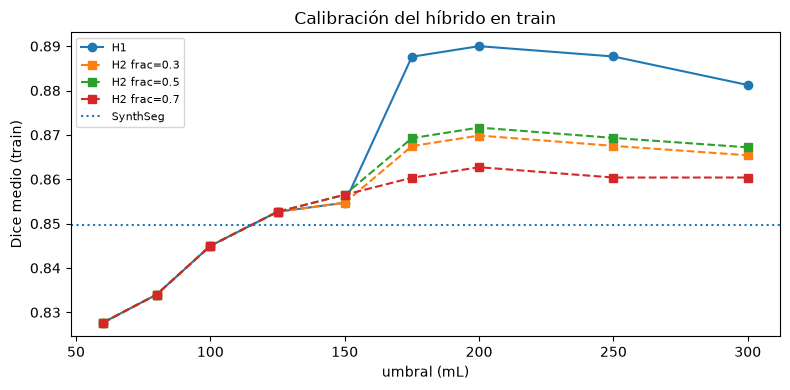

In [5]:
train = base[base.split == "train"]
val = base[base.split == "val"]
test = base[base.split == "test"]

UMBRALES = [60, 80, 100, 125, 150, 175, 200, 250, 300]
FRACS = [0.3, 0.5, 0.7]
grid = []
for variante in ["H1", "H2"]:
    for u in UMBRALES:
        for f in (FRACS if variante == "H2" else [np.nan]):
            h = evaluar_hibrido(train, variante, u, f)
            err = ((h.vol_Hibrido - h.vol_gt) / h.vol_gt * 100).abs()
            grid.append({"variante": variante, "umbral": u, "frac": f,
                         "dice_media_train": h.dice_Hibrido.mean(), "err_abs_mediana_train": err.median()})
grid = pd.DataFrame(grid).sort_values("dice_media_train", ascending=False)
grid.to_csv(FIG_DIR / "calibracion_train.csv", index=False)
display(grid.head(10).round(3))

mejor = {v: grid[grid.variante == v].iloc[0] for v in ["H1", "H2"]}
for v, r in mejor.items():
    print(f"{v}: umbral {r.umbral:.0f} mL, frac {r.frac} | Dice train {r.dice_media_train:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
g1 = grid[grid.variante == "H1"].sort_values("umbral")
ax.plot(g1.umbral, g1.dice_media_train, "o-", label="H1")
for f in FRACS:
    g2 = grid[(grid.variante == "H2") & (grid.frac == f)].sort_values("umbral")
    ax.plot(g2.umbral, g2.dice_media_train, "s--", label=f"H2 frac={f}")
ax.axhline(train.dice_SynthSeg.mean(), color="tab:blue", ls=":", label="SynthSeg")
ax.set_xlabel("umbral (mL)"); ax.set_ylabel("Dice medio (train)"); ax.legend(fontsize=8)
ax.set_title("Calibración del híbrido en train")
plt.tight_layout(); guardar("calibracion_train"); plt.show()

## 5. Selección de variante en validación

In [6]:
sel = []
for v, r in mejor.items():
    h = evaluar_hibrido(val, v, r.umbral, r.frac)
    sel.append({"variante": v, "umbral": r.umbral, "frac": r.frac, "dice_media_val": h.dice_Hibrido.mean(),
                "err_abs_mediana_val": ((h.vol_Hibrido - h.vol_gt) / h.vol_gt * 100).abs().median()})
sel = pd.DataFrame(sel)
sel["dice_SynthSeg_val"] = val.dice_SynthSeg.mean()
sel["dice_Clasico_val"] = val.dice_Clasico.mean()
display(sel.round(3))
sel.to_csv(FIG_DIR / "seleccion_validacion.csv", index=False)

final = sel.sort_values(["dice_media_val", "variante"], ascending=[False, True]).iloc[0]
VARIANTE, UMBRAL, FRAC = final.variante, float(final.umbral), final.frac
print(f"Híbrido final: {VARIANTE}, umbral {UMBRAL:.0f} mL, frac {FRAC}")

,variante,umbral,frac,dice_media_val,err_abs_mediana_val,dice_SynthSeg_val,dice_Clasico_val
0,H1,200,NaN,0.901,11.131,0.901,0.731
1,H2,200,0.5,0.901,11.131,0.901,0.731


Híbrido final: H1, umbral 200 mL, frac nan


## 6. Evaluación final en test

In [7]:
ht = evaluar_hibrido(test, VARIANTE, UMBRAL, FRAC)
METODOS = ["SynthSeg", "Clasico", "Hibrido"]
for n in METODOS:
    ht[f"err_{n}_%"] = (ht[f"vol_{n}"] - ht.vol_gt) / ht.vol_gt * 100
ht.to_csv(FIG_DIR / "test_por_caso.csv", index=False)


def ic_bootstrap(x, n=5000, seed=SEED):
    x = np.asarray(x)[~np.isnan(x)]
    if len(x) < 2:
        return np.nan, np.nan
    r = np.random.default_rng(seed)
    m = [r.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, 2.5), np.percentile(m, 97.5)


rows = []
for grupo, sub in [("total", ht)] + list(ht.groupby("rango", observed=True)):
    for n in METODOS:
        lo, hi = ic_bootstrap(sub[f"dice_{n}"])
        d = sub[f"vol_{n}"] - sub.vol_gt
        rows.append({"rango": grupo, "metodo": n, "n": len(sub),
                     "dice_media": sub[f"dice_{n}"].mean(), "IC95_low": lo, "IC95_high": hi,
                     "dice_mediana": sub[f"dice_{n}"].median(), "dice_min": sub[f"dice_{n}"].min(),
                     "err_vol_abs_mediana_%": sub[f"err_{n}_%"].abs().median(),
                     "hd95_mediana_mm": sub[f"hd95_{n}"].median(),
                     "sesgo_ml": d.mean(), "LoA_ml": 1.96 * d.std(),
                     "casos_dice<0.5": int((sub[f"dice_{n}"] < 0.5).sum())})
res_test = pd.DataFrame(rows)
res_test.to_csv(FIG_DIR / "resultados_test.csv", index=False)
display(res_test.round(3))

print("Prueba de Wilcoxon pareada (Dice, test):")
for a, b in [("Hibrido", "SynthSeg"), ("Hibrido", "Clasico"), ("SynthSeg", "Clasico")]:
    x, y = ht[f"dice_{a}"], ht[f"dice_{b}"]
    try:
        p = wilcoxon(x, y).pvalue
    except ValueError:
        p = np.nan
    print(f"  {a} vs {b}: diferencia media {np.mean(x - y):+.3f}, p = {p:.3f}")

,rango,metodo,n,dice_media,IC95_low,IC95_high,dice_mediana,dice_min,err_vol_abs_mediana_%,hd95_mediana_mm,sesgo_ml,LoA_ml,casos_dice<0.5
0,total,SynthSeg,9,0.825,0.652,0.942,0.902,0.197,5.438,7.550,-16.985,58.998,1
1,total,Clasico,9,0.736,0.626,0.837,0.796,0.440,10.651,15.748,2.867,39.285,1
2,total,Hibrido,9,0.819,0.648,0.932,0.902,0.197,8.661,7.550,-14.722,62.672,1
3,pequeño,SynthSeg,3,0.886,0.780,0.976,0.902,0.780,4.892,7.550,-0.962,4.737,0
4,pequeño,Clasico,3,0.564,0.440,0.628,0.623,0.440,30.956,20.116,7.623,19.784,1
5,pequeño,Hibrido,3,0.886,0.780,0.976,0.902,0.780,4.892,7.550,-0.962,4.737,0
6,mediano,SynthSeg,4,0.732,0.389,0.972,0.875,0.197,19.669,12.007,-32.218,82.749,1
7,mediano,Clasico,4,0.786,0.651,0.884,0.825,0.583,16.809,14.887,-5.476,55.852,0
8,mediano,Hibrido,4,0.732,0.389,0.972,0.875,0.197,19.669,12.007,-32.218,82.749,1
9,grande,SynthSeg,2,0.922,0.874,0.970,0.922,0.874,6.675,5.275,-10.554,20.415,0


Prueba de Wilcoxon pareada (Dice, test):
  Hibrido vs SynthSeg: diferencia media -0.007, p = 1.000
  Hibrido vs Clasico: diferencia media +0.083, p = 0.461
  SynthSeg vs Clasico: diferencia media +0.090, p = 0.359


## 7. Figuras finales (test)

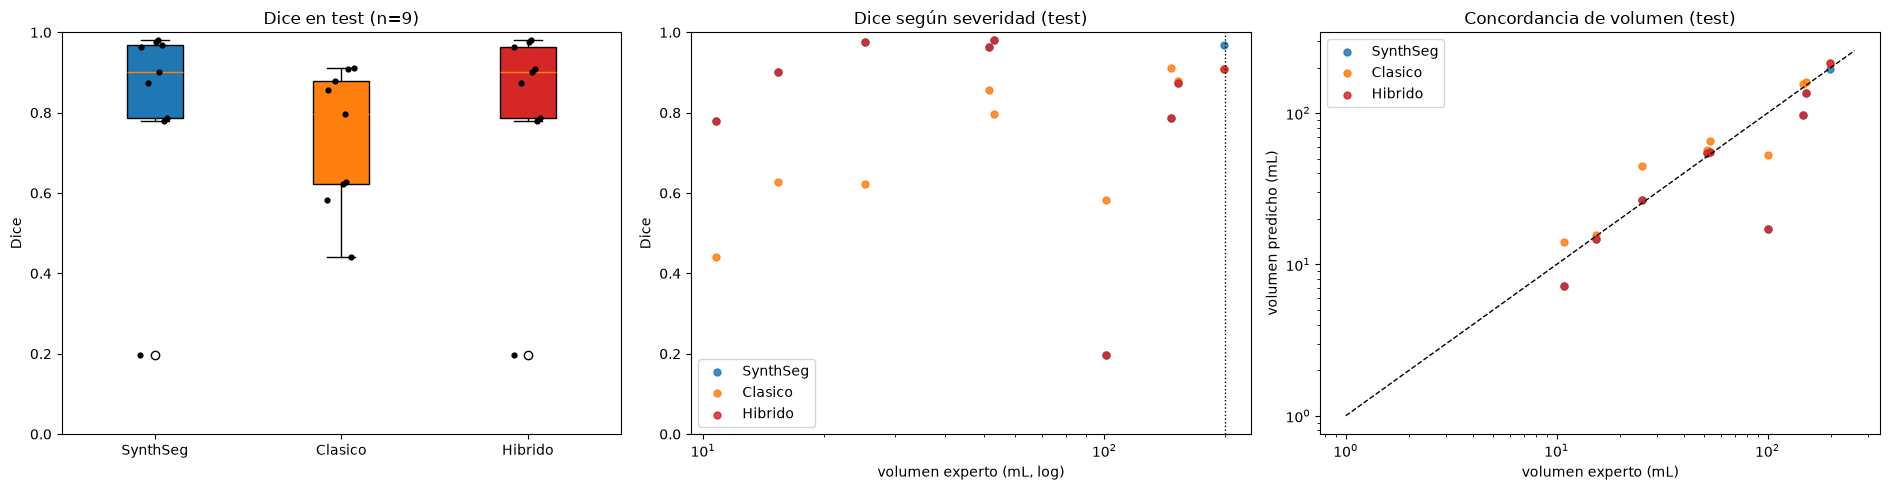

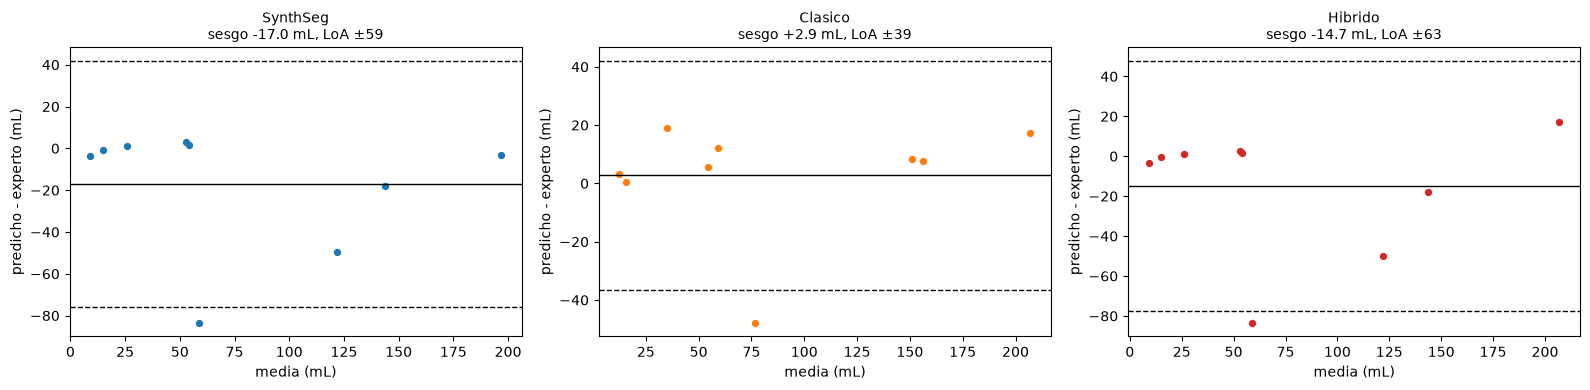

In [8]:
col = {"SynthSeg": "tab:blue", "Clasico": "tab:orange", "Hibrido": "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

bp = ax[0].boxplot([ht[f"dice_{n}"] for n in METODOS], patch_artist=True)
ax[0].set_xticks(range(1, len(METODOS) + 1)); ax[0].set_xticklabels(METODOS)
for b, n in zip(bp["boxes"], METODOS):
    b.set_facecolor(col[n])
for i, n in enumerate(METODOS):
    ax[0].scatter(np.full(len(ht), i + 1) + np.random.default_rng(0).uniform(-0.08, 0.08, len(ht)),
                  ht[f"dice_{n}"], s=12, color="k", zorder=3)
ax[0].set_ylim(0, 1); ax[0].set_ylabel("Dice"); ax[0].set_title(f"Dice en test (n={len(ht)})")

for n in METODOS:
    ax[1].scatter(ht.vol_gt, ht[f"dice_{n}"], s=25, color=col[n], label=n, alpha=0.85)
ax[1].axvline(UMBRAL, color="k", ls=":", lw=1)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1); ax[1].legend()
ax[1].set_xlabel("volumen experto (mL, log)"); ax[1].set_ylabel("Dice"); ax[1].set_title("Dice según severidad (test)")

lim = [1, ht[["vol_gt"] + [f"vol_{n}" for n in METODOS]].max().max() * 1.2]
for n in METODOS:
    ax[2].scatter(ht.vol_gt, ht[f"vol_{n}"], s=25, color=col[n], label=n, alpha=0.85)
ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].legend()
ax[2].set_xlabel("volumen experto (mL)"); ax[2].set_ylabel("volumen predicho (mL)")
ax[2].set_title("Concordancia de volumen (test)")
plt.tight_layout(); guardar("test_resumen"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for a, n in zip(axes, METODOS):
    m, d = (ht[f"vol_{n}"] + ht.vol_gt) / 2, ht[f"vol_{n}"] - ht.vol_gt
    s_, sd = d.mean(), d.std()
    a.scatter(m, d, s=18, color=col[n])
    for y, ls in [(s_, "-"), (s_ + 1.96 * sd, "--"), (s_ - 1.96 * sd, "--")]:
        a.axhline(y, color="k", ls=ls, lw=1)
    a.set_title(f"{n}\nsesgo {s_:+.1f} mL, LoA ±{1.96 * sd:.0f}", fontsize=10)
    a.set_xlabel("media (mL)"); a.set_ylabel("predicho - experto (mL)")
plt.tight_layout(); guardar("test_bland_altman"); plt.show()

## 8. Casos de test

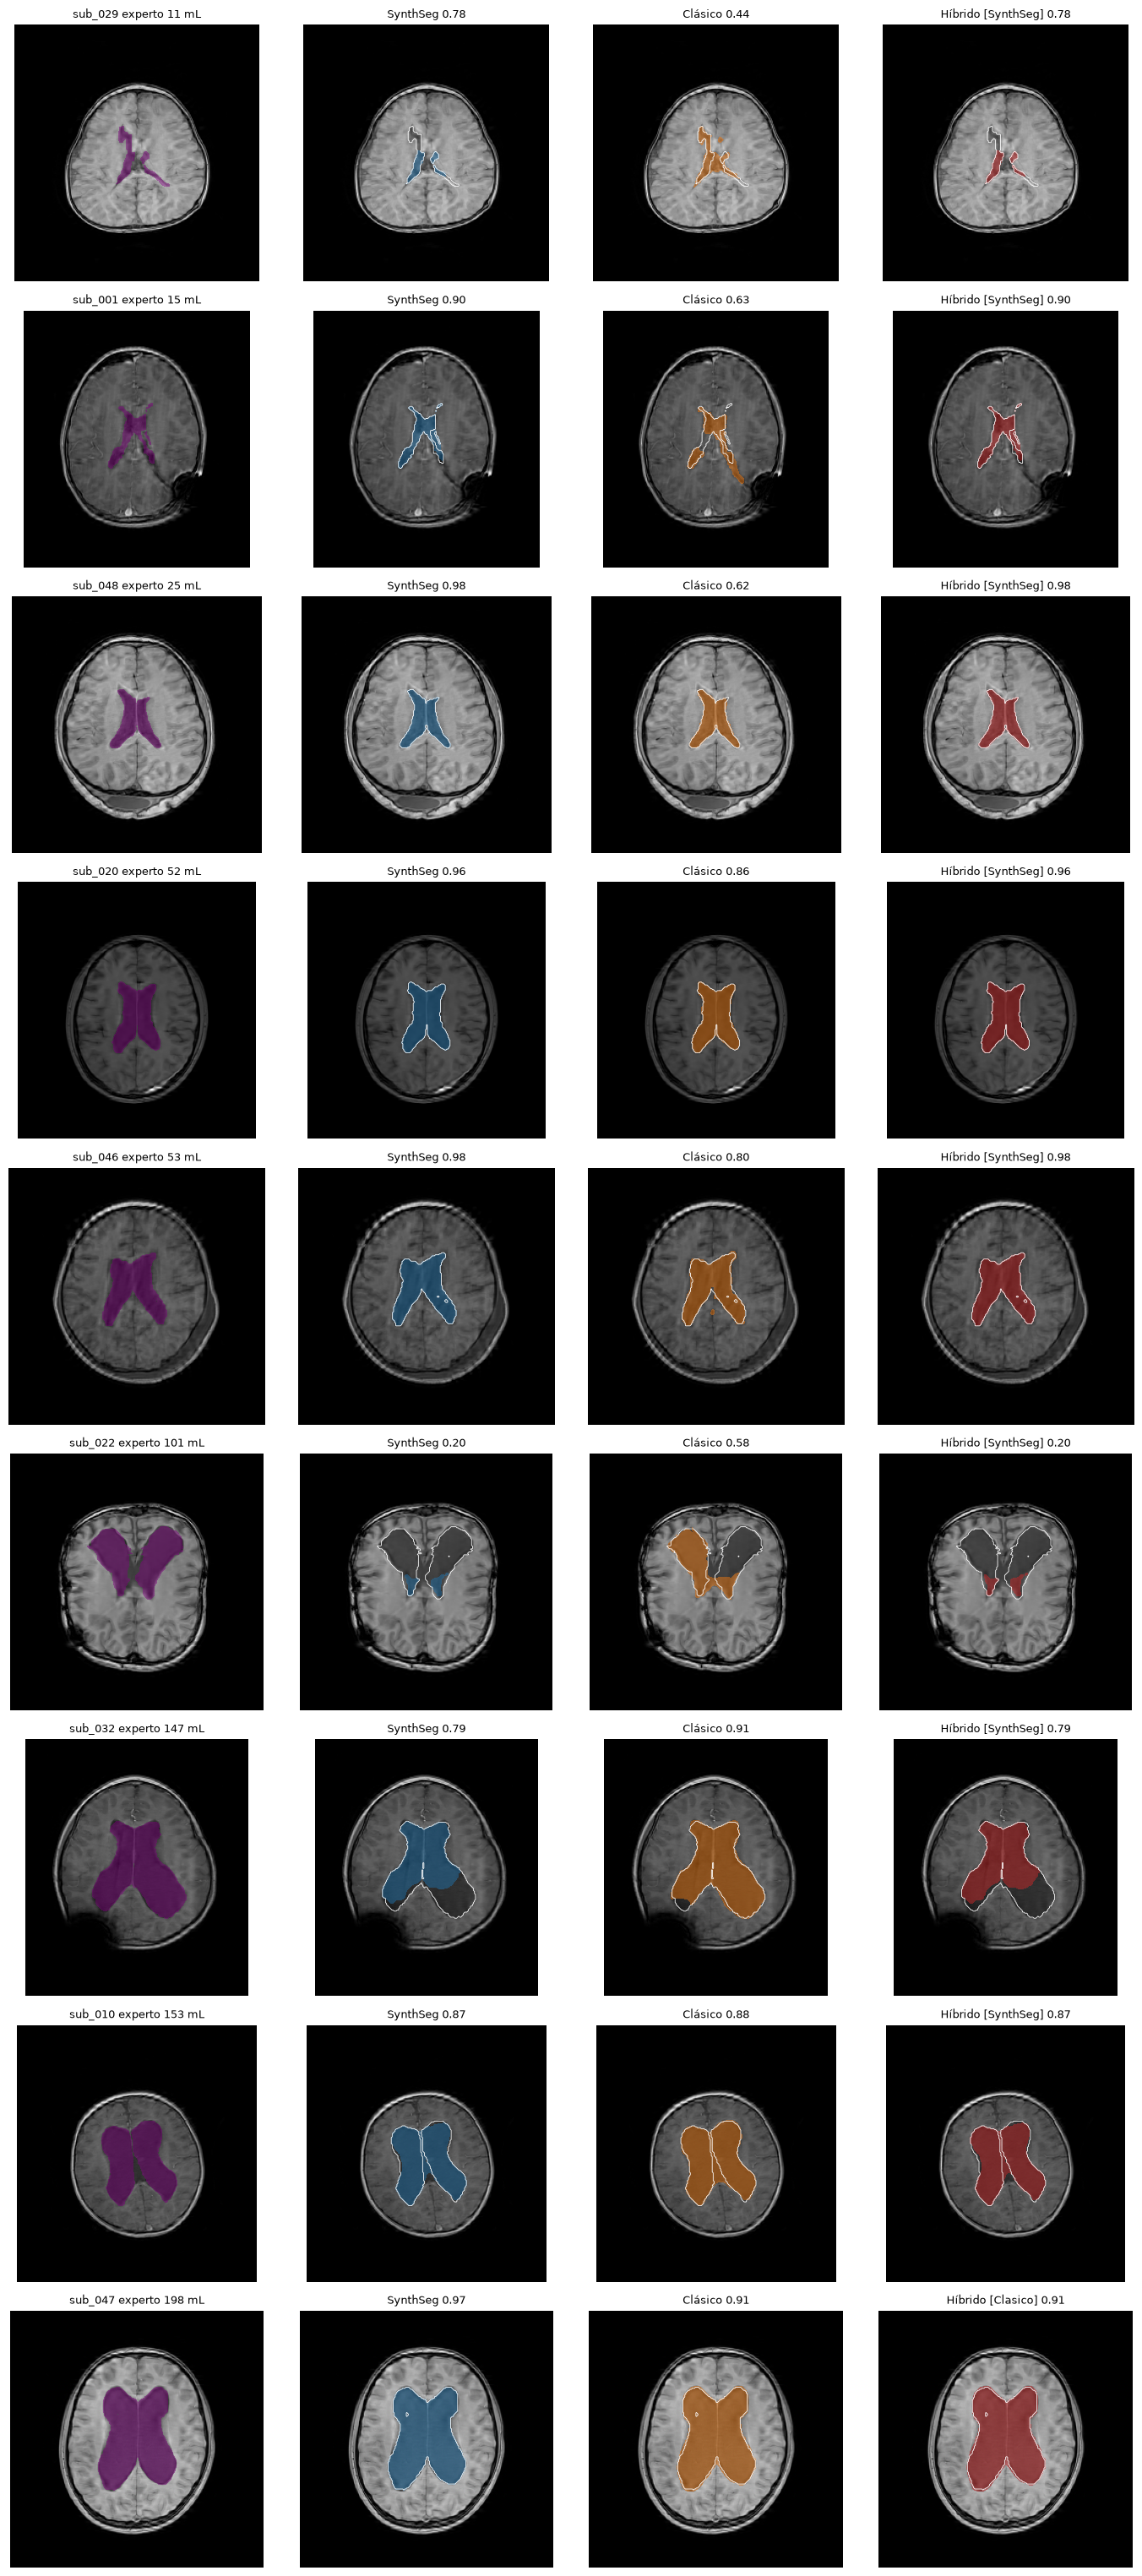

Archivos en C:\Users\Usuario\Desktop\Vida_Academica\2026-II\FIB\hykid\outputs\figuras_06_final
  base_metricas.csv
  calibracion_train.csv
  calibracion_train.png
  particion.csv
  resultados_test.csv
  seleccion_validacion.csv
  test_bland_altman.png
  test_casos.png
  test_por_caso.csv
  test_resumen.png


In [9]:
orden = ht.sort_values("vol_gt")
fig, axes = plt.subplots(len(orden), 4, figsize=(14, 3.4 * len(orden)), squeeze=False)
for row, (_, r) in zip(axes, orden.iterrows()):
    s = next(x for x in scans if x.parent.name == r.subject and x.name == r.scan)
    img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
    g = load_seg(s / "segmentation" / "gt.nii.gz")[0] == 4
    ss = synthseg(s, g.shape)
    cl = clasico_completo(img, zooms, g.shape)
    hb = cl if r.elige == "Clasico" else ss
    k = int(np.argmax(g.sum(axis=(0, 1))))
    sl = lambda a: np.rot90(a[:, :, k])
    for a, (m, t, c) in zip(row, [(g, f"{r.subject} experto {r.vol_gt:.0f} mL", "purple"),
                                   (ss, f"SynthSeg {r.dice_SynthSeg:.2f}", col["SynthSeg"]),
                                   (cl, f"Clásico {r.dice_Clasico:.2f}", col["Clasico"]),
                                   (hb, f"Híbrido [{r.elige}] {r.dice_Hibrido:.2f}", col["Hibrido"])]):
        a.imshow(sl(img), cmap="gray")
        a.contourf(sl(m), levels=[0.5, 1.5], colors=[c], alpha=0.45)
        if not t.startswith("sub"):
            a.contour(sl(g), levels=[0.5], colors="white", linewidths=0.6)
        a.set_title(t, fontsize=9)
        a.axis("off")
plt.tight_layout(); guardar("test_casos"); plt.show()

print("Archivos en", FIG_DIR)
for f in sorted(FIG_DIR.iterdir()):
    print(" ", f.name)

In [10]:
K = 5
REPETICIONES = 10

def particion_kfold(base, k, seed):
    pac = base.groupby("subject").agg(vol=("vol_gt", "max")).reset_index()
    pac["rango"] = pd.cut(pac.vol, [0, 30, 150, np.inf], labels=["pequeño", "mediano", "grande"])
    r = np.random.default_rng(seed)
    fold = {}
    for _, g in pac.groupby("rango", observed=True):
        ids = list(g.subject)
        r.shuffle(ids)
        for i, s in enumerate(ids):
            fold[s] = i % k
    return base.subject.map(fold)


def calibrar(df):
    mejor, mejor_d = None, -1
    for variante in ["H1", "H2"]:
        for u in UMBRALES:
            for f in (FRACS if variante == "H2" else [np.nan]):
                d = evaluar_hibrido(df, variante, u, f).dice_Hibrido.mean()
                if d > mejor_d + 1e-9:
                    mejor, mejor_d = (variante, u, f), d
    return mejor


preds, params = [], []
for rep in range(REPETICIONES):
    folds = particion_kfold(base, K, SEED + rep)
    for k in range(K):
        tr, te = base[folds != k], base[folds == k]
        variante, u, f = calibrar(tr)
        h = evaluar_hibrido(te, variante, u, f)
        h["rep"], h["fold"] = rep, k
        preds.append(h)
        params.append({"rep": rep, "fold": k, "variante": variante, "umbral": u, "frac": f, "n_test": len(te)})

cv = pd.concat(preds, ignore_index=True)
params = pd.DataFrame(params)
cv.to_csv(FIG_DIR / "cv_predicciones.csv", index=False)
params.to_csv(FIG_DIR / "cv_parametros.csv", index=False)
print("Parámetros elegidos en cada fold:")
display(params.groupby(["variante", "umbral"]).size().rename("veces").reset_index())

Parámetros elegidos en cada fold:


,variante,umbral,veces
0,H1,175,8
1,H1,200,23
2,H1,250,10
3,H2,175,1
4,H2,200,8


In [11]:
por_caso = cv.groupby(["subject", "scan"]).agg(
    vol_gt=("vol_gt", "first"), rango=("rango", "first"),
    **{f"dice_{n}": (f"dice_{n}", "mean") for n in METODOS},
    **{f"vol_{n}": (f"vol_{n}", "mean") for n in METODOS},
    **{f"hd95_{n}": (f"hd95_{n}", "mean") for n in METODOS},
    pct_clasico=("elige", lambda x: (x == "Clasico").mean()),
).reset_index()
for n in METODOS:
    por_caso[f"err_{n}_%"] = (por_caso[f"vol_{n}"] - por_caso.vol_gt) / por_caso.vol_gt * 100
por_caso.to_csv(FIG_DIR / "cv_por_caso.csv", index=False)

rows = []
for grupo, sub in [("total", por_caso)] + list(por_caso.groupby("rango", observed=True)):
    for n in METODOS:
        lo, hi = ic_bootstrap(sub[f"dice_{n}"])
        d = sub[f"vol_{n}"] - sub.vol_gt
        rows.append({"rango": grupo, "metodo": n, "n": len(sub),
                     "dice_media": sub[f"dice_{n}"].mean(), "IC95_low": lo, "IC95_high": hi,
                     "dice_mediana": sub[f"dice_{n}"].median(), "dice_min": sub[f"dice_{n}"].min(),
                     "err_vol_abs_mediana_%": sub[f"err_{n}_%"].abs().median(),
                     "hd95_mediana_mm": sub[f"hd95_{n}"].median(),
                     "sesgo_ml": d.mean(), "LoA_ml": 1.96 * d.std(),
                     "casos_dice<0.5": int((sub[f"dice_{n}"] < 0.5).sum())})
res_cv = pd.DataFrame(rows)
res_cv.to_csv(FIG_DIR / "cv_resultados.csv", index=False)
display(res_cv.round(3))

print(f"Wilcoxon pareado (Dice por caso, {K}-fold x {REPETICIONES}):")
for a, b in [("Hibrido", "SynthSeg"), ("Hibrido", "Clasico"), ("SynthSeg", "Clasico")]:
    x, y = por_caso[f"dice_{a}"], por_caso[f"dice_{b}"]
    try:
        p = wilcoxon(x, y).pvalue
    except ValueError:
        p = np.nan
    print(f"  {a} vs {b}: diferencia media {np.mean(x - y):+.3f}, p = {p:.4f}")

,rango,metodo,n,dice_media,IC95_low,IC95_high,dice_mediana,dice_min,err_vol_abs_mediana_%,hd95_mediana_mm,sesgo_ml,LoA_ml,casos_dice<0.5
0,total,SynthSeg,45,0.849,0.790,0.896,0.903,0.062,7.998,3.317,-27.250,128.178,2
1,total,Clasico,45,0.669,0.588,0.745,0.796,0.000,21.239,16.248,4.380,114.581,10
2,total,Hibrido,45,0.861,0.809,0.902,0.905,0.197,7.189,4.583,-3.893,83.376,2
3,pequeño,SynthSeg,14,0.886,0.851,0.915,0.897,0.741,5.756,2.532,-0.800,5.801,0
4,pequeño,Clasico,14,0.381,0.271,0.488,0.428,0.000,50.775,30.272,14.326,64.785,9
5,pequeño,Hibrido,14,0.844,0.747,0.910,0.897,0.307,5.756,2.532,6.984,59.548,1
6,mediano,SynthSeg,20,0.887,0.800,0.947,0.952,0.197,5.006,3.317,-9.573,42.616,1
7,mediano,Clasico,20,0.827,0.789,0.860,0.861,0.583,13.869,10.839,10.758,47.777,0
8,mediano,Hibrido,20,0.887,0.800,0.947,0.952,0.197,5.006,3.317,-9.573,42.616,1
9,grande,SynthSeg,11,0.735,0.576,0.859,0.839,0.062,25.601,9.434,-93.055,210.555,1


Wilcoxon pareado (Dice por caso, 5-fold x 10):
  Hibrido vs SynthSeg: diferencia media +0.011, p = 0.4990
  Hibrido vs Clasico: diferencia media +0.192, p = 0.0000
  SynthSeg vs Clasico: diferencia media +0.180, p = 0.0001


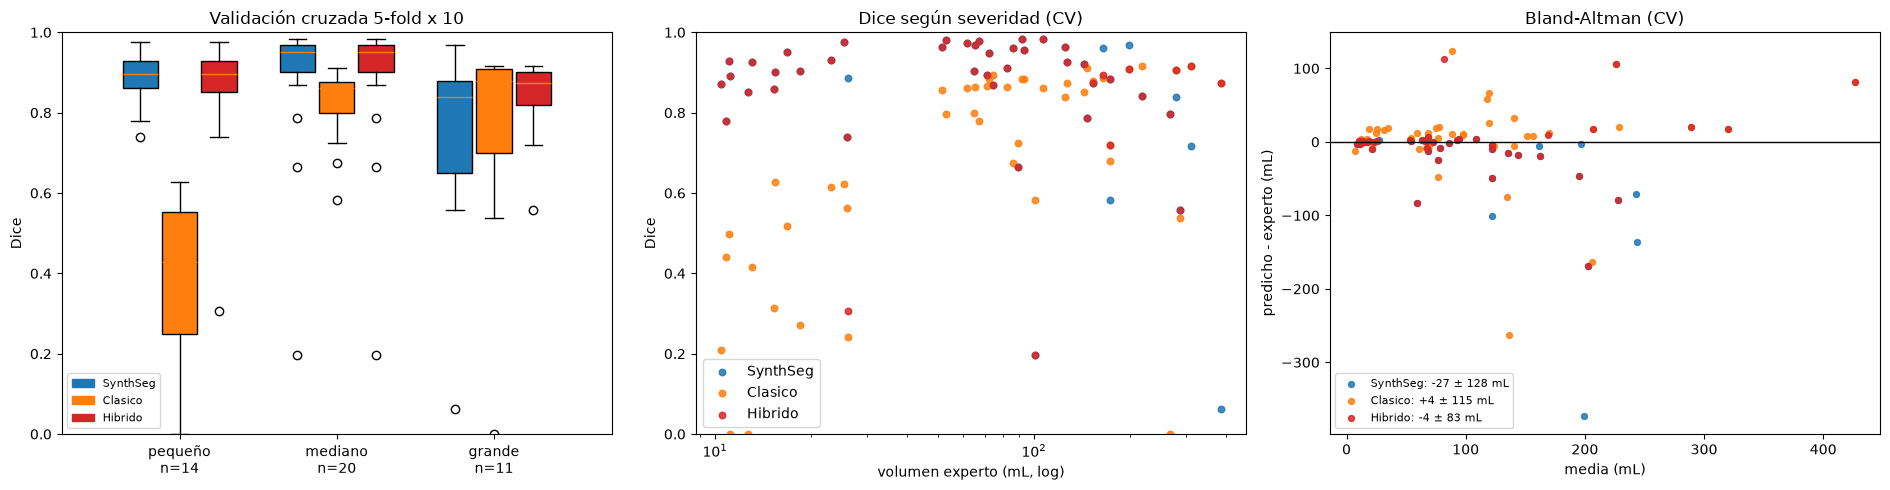

Casos donde el híbrido eligió el clásico al menos una vez:


,subject,scan,vol_gt,pct_clasico,dice_SynthSeg,dice_Clasico,dice_Hibrido
41,sub_045,scan_01,26.08,0.9,0.89,0.24,0.31
27,sub_031,scan_01,164.04,0.9,0.96,0.89,0.89
37,sub_041,scan_01,173.15,1.0,0.58,0.72,0.72
43,sub_047,scan_01,198.38,1.0,0.97,0.91,0.91
2,sub_004,scan_01,278.86,1.0,0.84,0.91,0.91
9,sub_012,scan_01,311.22,1.0,0.72,0.92,0.92
11,sub_015,scan_01,385.69,1.0,0.06,0.88,0.88


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
rangos = list(por_caso.rango.cat.categories)
w = 0.25
for i, n in enumerate(METODOS):
    pos = np.arange(len(rangos)) + (i - 1) * w
    bp = ax[0].boxplot([por_caso.loc[por_caso.rango == r, f"dice_{n}"] for r in rangos],
                       positions=pos, widths=w * 0.9, patch_artist=True)
    for b in bp["boxes"]:
        b.set_facecolor(col[n])
ax[0].set_xticks(range(len(rangos)))
ax[0].set_xticklabels([f"{r}\nn={(por_caso.rango == r).sum()}" for r in rangos])
ax[0].set_ylim(0, 1); ax[0].set_ylabel("Dice")
ax[0].set_title(f"Validación cruzada {K}-fold x {REPETICIONES}")
ax[0].legend([plt.Rectangle((0, 0), 1, 1, color=col[n]) for n in METODOS], METODOS, fontsize=8)

for n in METODOS:
    ax[1].scatter(por_caso.vol_gt, por_caso[f"dice_{n}"], s=22, color=col[n], label=n, alpha=0.85)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1); ax[1].legend()
ax[1].set_xlabel("volumen experto (mL, log)"); ax[1].set_ylabel("Dice"); ax[1].set_title("Dice según severidad (CV)")

for n in METODOS:
    m, d = (por_caso[f"vol_{n}"] + por_caso.vol_gt) / 2, por_caso[f"vol_{n}"] - por_caso.vol_gt
    ax[2].scatter(m, d, s=18, color=col[n], label=f"{n}: {d.mean():+.0f} ± {1.96 * d.std():.0f} mL", alpha=0.85)
ax[2].axhline(0, color="k", lw=1)
ax[2].set_xlabel("media (mL)"); ax[2].set_ylabel("predicho - experto (mL)")
ax[2].set_title("Bland-Altman (CV)"); ax[2].legend(fontsize=8)
plt.tight_layout(); guardar("cv_resumen"); plt.show()

print("Casos donde el híbrido eligió el clásico al menos una vez:")
display(por_caso[por_caso.pct_clasico > 0].sort_values("vol_gt")[
    ["subject", "scan", "vol_gt", "pct_clasico", "dice_SynthSeg", "dice_Clasico", "dice_Hibrido"]].round(2))

## Notas para el informe

- El test se evalúa una sola vez con los parámetros elegidos en train y validación.
- Con ~9 estudios en test, los intervalos de confianza son anchos: conviene reportar también los resultados en los 45 estudios (notebook 05) como análisis complementario.
- El método clásico se desarrolló mirando 8 casos; para evitar fuga, esos casos se fuerzan a train.